In [6]:
import sys, warnings
sys.path.append("..")
warnings.filterwarnings("ignore", category=DeprecationWarning)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
from lifetimes import BetaGeoFitter, GammaGammaFitter
from lifetimes.utils import calibration_and_holdout_data, summary_data_from_transaction_data
from lifetimes.plotting import plot_calibration_purchases_vs_holdout_purchases
from src.db import query

sns.set_theme(style="whitegrid")
DATA_END = pd.Timestamp("2011-12-09")

# One row per customer per purchase day (same definition of a real purchase as elsewhere)
tx = query("""
SELECT f.customer_key, d.full_date AS order_date, SUM(f.line_amount) AS amount
FROM gold.fact_sales f
JOIN gold.dim_date d USING (date_key)
WHERE NOT f.is_cancellation AND f.is_product_line AND f.quantity > 0 AND f.unit_price > 0
GROUP BY 1, 2
""")
tx["order_date"] = pd.to_datetime(tx["order_date"])
tx = tx[tx["amount"] > 0]
print(f"{len(tx):,} purchase days, {tx['customer_key'].nunique():,} customers")

32,878 purchase days, 5,852 customers


3,993 customers, 61.2% lapsed


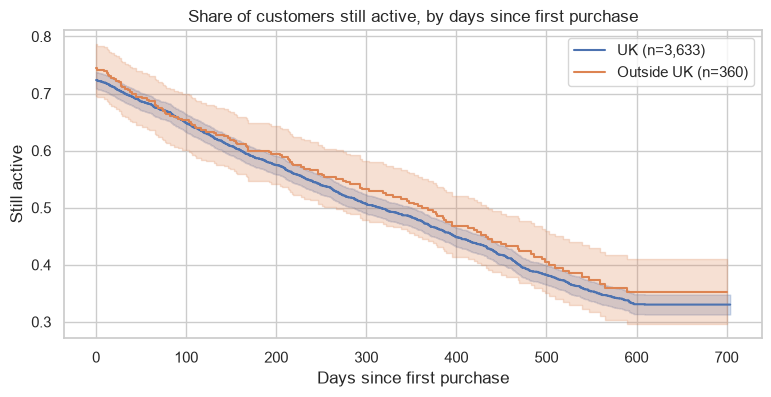

log-rank p-value: 0.4212610135002899


In [7]:
cust = tx.groupby("customer_key")["order_date"].agg(first="min", last="max").reset_index()
country = query("SELECT customer_key, (country = 'United Kingdom') AS is_uk FROM gold.dim_customer")
cust = cust.merge(country, on="customer_key")

# Customers first seen Jan 2010 to Jun 2011 only: Dec 2009 includes people who joined
# before the data starts, and later customers have under 6 months of follow-up.
cust = cust[(cust["first"] >= "2010-01-01") & (cust["first"] <= "2011-06-09")].copy()

# Lapsed = last purchase more than 90 days before the end of the data.
# Lapsed customers are observed until their last purchase; the rest are still active
# at the end of the data, so they are censored there.
cust["lapsed"] = ((DATA_END - cust["last"]).dt.days > 90).astype(int)
cust["duration"] = (cust["last"] - cust["first"]).dt.days.where(
    cust["lapsed"] == 1, (DATA_END - cust["first"]).dt.days
)
print(f"{len(cust):,} customers, {cust['lapsed'].mean():.1%} lapsed")

fig, ax = plt.subplots(figsize=(9, 4))
for flag, label in [(True, "UK"), (False, "Outside UK")]:
    grp = cust[cust["is_uk"] == flag]
    KaplanMeierFitter().fit(grp["duration"], grp["lapsed"], label=f"{label} (n={len(grp):,})").plot_survival_function(ax=ax)
ax.set_title("Share of customers still active, by days since first purchase")
ax.set_xlabel("Days since first purchase")
ax.set_ylabel("Still active")
plt.show()

uk, other = cust[cust["is_uk"]], cust[~cust["is_uk"]]
print("log-rank p-value:", logrank_test(uk["duration"], other["duration"], uk["lapsed"], other["lapsed"]).p_value)

4,944 customers in the calibration period
Actual holdout purchases:    7753
Predicted holdout purchases: 7731
Correlation, actual vs predicted: 0.849


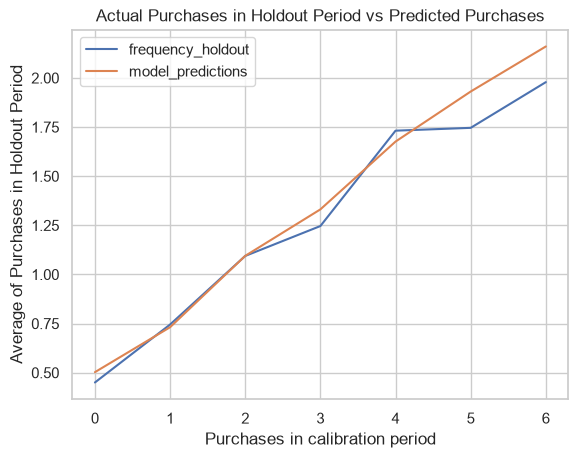

In [8]:
summary = calibration_and_holdout_data(
    tx, "customer_key", "order_date",
    calibration_period_end="2011-06-09",
    observation_period_end="2011-12-09",
    monetary_value_col="amount",
)
bgf = BetaGeoFitter(penalizer_coef=0.001)
bgf.fit(summary["frequency_cal"], summary["recency_cal"], summary["T_cal"])
summary["predicted_holdout"] = bgf.conditional_expected_number_of_purchases_up_to_time(
    summary["duration_holdout"], summary["frequency_cal"], summary["recency_cal"], summary["T_cal"]
)

print(f"{len(summary):,} customers in the calibration period")
print("Actual holdout purchases:   ", round(summary["frequency_holdout"].sum()))
print("Predicted holdout purchases:", round(summary["predicted_holdout"].sum()))
print("Correlation, actual vs predicted:",
      round(summary[["frequency_holdout", "predicted_holdout"]].corr().iloc[0, 1], 3))

plot_calibration_purchases_vs_holdout_purchases(bgf, summary)
plt.show()

In [10]:
one_and_done = ((cust["duration"] == 0) & (cust["lapsed"] == 1)).mean()
print(f"Lapsed after a single purchase: {one_and_done:.1%} of customers")

Lapsed after a single purchase: 27.4% of customers


In [13]:
full = summary_data_from_transaction_data(
    tx, "customer_key", "order_date", monetary_value_col="amount",
    observation_period_end="2011-12-09",
)
bgf_full = BetaGeoFitter(penalizer_coef=0.001).fit(full["frequency"], full["recency"], full["T"])
full["expected_purchases_6m"] = bgf_full.conditional_expected_number_of_purchases_up_to_time(
    180, full["frequency"], full["recency"], full["T"]
)

# Spend per purchase: Gamma-Gamma needs repeat customers, so it is fitted and scored only for them.
# Winsorizing at the 99th percentile stops a handful of giant accounts from driving the estimate.
repeat = full[full["frequency"] > 0].copy()
cap = repeat["monetary_value"].quantile(0.99)
repeat["monetary_capped"] = repeat["monetary_value"].clip(upper=cap)
print("Correlation between frequency and spend per purchase:",
      round(repeat[["frequency", "monetary_capped"]].corr().iloc[0, 1], 3))
print(f"Spend per purchase capped at {cap:,.0f}")

ggf = GammaGammaFitter(penalizer_coef=0.001).fit(repeat["frequency"], repeat["monetary_capped"])
repeat["expected_spend"] = ggf.conditional_expected_average_profit(repeat["frequency"], repeat["monetary_capped"])

full["expected_spend"] = repeat["expected_spend"]
full["clv_6m"] = full["expected_purchases_6m"] * full["expected_spend"]   # NaN for single-purchase customers

scored = full.dropna(subset=["clv_6m"])
print(f"\nValue scored for {len(scored):,} repeat customers; {full['clv_6m'].isna().sum():,} single-purchase customers are not scored")
print(scored["clv_6m"].describe().round(2))
print("Negative values:", (scored["clv_6m"] < 0).sum())

top = scored["clv_6m"].sort_values(ascending=False)
print(f"\nTop 10% of repeat customers hold {top.head(len(top) // 10).sum() / top.sum():.0%} of predicted 6-month value")

Correlation between frequency and spend per purchase: 0.183
Spend per purchase capped at 2,164

Value scored for 4,179 repeat customers; 1,673 single-purchase customers are not scored
count     4179.00
mean       900.81
std       2413.22
min          0.00
25%        157.63
50%        387.54
75%        905.11
max      60632.34
Name: clv_6m, dtype: float64
Negative values: 0

Top 10% of repeat customers hold 52% of predicted 6-month value


In [11]:
print("Customers with clv_6m < 0:", (full["clv_6m"] < 0).sum())
print("...of which frequency == 0 (single purchase):", ((full["clv_6m"] < 0) & (full["frequency"] == 0)).sum())
print("Customers with frequency == 0:", (full["frequency"] == 0).sum(), "of", len(full))
print("\nSpend per purchase, repeat customers:")
print(repeat["monetary_value"].describe().round(2))
print("\nLowest 5 clv_6m:")
print(full.sort_values("clv_6m").head(5)[["frequency", "recency", "T", "monetary_value", "p_alive", "clv_6m"]])

Customers with clv_6m < 0: 1673
...of which frequency == 0 (single purchase): 1673
Customers with frequency == 0: 1673 of 5852

Spend per purchase, repeat customers:
count      4179.00
mean        442.26
std        2722.66
min           3.90
25%         185.38
50%         299.95
75%         441.17
max      168469.60
Name: monetary_value, dtype: float64

Lowest 5 clv_6m:
              frequency  recency    T  monetary_value  p_alive       clv_6m
customer_key                                                               
368                 0.0      0.0  0.0             0.0      1.0 -2192.416838
1091                0.0      0.0  1.0             0.0      1.0 -2160.022560
953                 0.0      0.0  1.0             0.0      1.0 -2160.022560
3175                0.0      0.0  1.0             0.0      1.0 -2160.022560
2850                0.0      0.0  2.0             0.0      1.0 -2128.584653


In [12]:
one_and_done = ((cust["duration"] == 0) & (cust["lapsed"] == 1)).mean()
print(f"Lapsed after a single purchase: {one_and_done:.1%} of customers")

Lapsed after a single purchase: 27.4% of customers


In [14]:
chk = summary[summary["frequency_cal"] > 0]
print(f"Repeat customers in calibration: {len(chk):,}")
print("Actual holdout purchases:   ", round(chk["frequency_holdout"].sum()))
print("Predicted holdout purchases:", round(chk["predicted_holdout"].sum()))

Repeat customers in calibration: 3,336
Actual holdout purchases:    7029
Predicted holdout purchases: 6922


## Findings
- 27.4% of customers buy once and never return. This is why the survival curves start near 0.72 instead of 1.0.
- Among customers who first bought between Jan 2010 and Jun 2011, 61.2% have lapsed (no purchase in the last 90 days of data). The curve shows no detectable difference between UK and non-UK customers (log-rank p = 0.42), but only 360 customers are non-UK, so the test has little power.
- BG/NBD purchase forecast, validated on a six-month holdout (trained to Jun 2011): 7,731 purchases predicted against 7,753 actual across 4,944 customers (customer-level correlation 0.85). The holdout window includes the Oct-Nov peak and the model has no seasonality, so this accuracy should not be assumed for a quiet period.
- For the 3,336 repeat customers the value model actually uses, the holdout forecast was 6,922 purchases against 7,029 actual (1.5% low).
- Value model (BG/NBD x Gamma-Gamma) is scored only for the 4,179 customers with at least one repeat purchase. Spend per purchase is capped at its 99th percentile (2,164) because a few accounts spend over 100,000 per purchase. Frequency and spend are weakly correlated (0.18), which breaks a model assumption, so spend estimates are approximate.
- Median predicted six-month value is about 388 per repeat customer; the top 10% hold 52% of predicted value.
- p_alive from BG/NBD averages 0.91 and is not used as a churn probability. Churn is modeled by the supervised model in notebook 04.